# Week5_ex2_analysis - 1-Slot Linear Motor: Thrust, and a Normal Force That Shouldn't Be There

![Week5_ex2 result](Images/Week5_ex2_result_image.png)

Magnetostatic 3D. Four NdFe35 magnets (20 x 200 x 3 mm, 4 mm apart, alternating ±z) sit on a 15 mm steel_1008 plate. One 100-turn coil (4 x 10 mm cross-section) wraps a 16 mm-wide slot, 5 mm above the magnets, carrying J = 3 A/mm² (1.2 A). With `stator_material = 0` the slot is air, so there is no iron on the coil side and the only force on the coil is the Lorentz force from the magnets' field. The original notebook reports it as a virtual force on coil + slot.

The two coil sides sit 2 mm inside the centers of two opposite poles, where the magnets' field is almost vertical, so the thrust should come straight from N·I·L·B_z. The arrangement is also mirror-symmetric: x → -x flips the pole polarity and the current direction in the coil sides together, which makes the z component of J × B odd in x. The normal force should therefore vanish. Both predictions (|F_x| ≈ 5.4 N from a 2D charge model, F_y ≈ F_z ≈ 0) were written down before the FEM table was opened; the sign of F_x depends on the terminal polarity, so only its size was predicted.

$$F_x=N I L\left(|\langle B_z\rangle_{left}|+|\langle B_z\rangle_{right}|\right),\qquad F_z=\int J_y B_x\,dV=0\ \ \text{(odd in }x\text{)}$$

## 2. FEM force on the coil

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Virtual force on coil + slot, read once from Force Table 1 in the AEDT GUI (Setup1 : LastAdaptive, newton)
F_fem = pd.Series({"Force_x": 4.785441, "Force_y": 0.039602, "Force_z": 1.184602})
pd.DataFrame({
    "FEM [N]": F_fem,
    "fraction of |Force_x| [%]": F_fem.abs() / abs(F_fem["Force_x"]) * 100,
}).round(4)

,FEM [N],fraction of |Force_x| [%]
Force_x,4.7854,100.0000
Force_y,0.0396,0.8276
Force_z,1.1846,24.7543


## 3. Charge model vs FEM

The magnets are modelled as surface charge ±M on their faces. The steel plate is treated as an infinitely permeable plane at its top surface, so each magnet's bottom-face charge cancels against its own image and the top-face charge gets an opposite image 6 mm below it. The 2D version (infinitely long magnets) was the blind prediction. The 3D version uses the closed-form field of a charged rectangle, so it includes the fall-off at the magnet ends (y = ±100 mm) where the coil's straight sides still run. The last step lets each magnet's magnetization respond to the field inside it, M = μr·Hc + (μr − 1)·H, which matters for thin magnets because their own demagnetizing field is strong.

In [2]:
# 2. Model constants -- NdFe35 mu_r read once from the AEDT material library, Hc as set in the original notebook.
#    Lengths in mm; the coil and magnet positions follow the original notebook's geometry after both moves.
mu0 = 4e-7 * np.pi
mu_r, Hc = 1.0997785406, 890000
chi = mu_r - 1
M0 = mu_r * Hc
NI = 3 * (4 * 10) / 100 * 100            # J * area / turns * turns = 120 A-turns
L = 0.200                                  # straight length of each coil side [m]
depth = 200.0
magnets = [(-46, -26, +1), (-22, -2, -1), (2, 22, +1), (26, 46, -1)]   # (x1, x2, +1 = N up)
z_top, z_img = 10.5, 4.5                   # top-face charge and its image below the plate surface (z = 7.5)
sides = [(-12, -8), (8, 12)]               # coil sides in x
z_coil = (15.5, 25.5)

# 3. 2D field (magnets infinitely long in y) -- the blind prediction
def Bz_2d(x, z, Ms):
    b = 0.0
    for (x1, x2, s), M in zip(magnets, Ms):
        for z0, q in ((z_top, 1), (z_img, -1)):
            dz = z - z0
            b = b + s * q * M / (2 * np.pi) * (np.arctan((x - x1) / dz) - np.arctan((x - x2) / dz))
    return mu0 * b

def thrust_2d(Ms):
    total = 0.0
    for xa, xb in sides:
        X, Z = np.meshgrid(np.linspace(xa, xb, 41), np.linspace(*z_coil, 101))
        total += abs(Bz_2d(X, Z, Ms).mean())
    return NI * L * total

# 4. 3D field of a uniformly charged rectangle, summed over the magnets and their images
def hz_rect(x, y, z, x1, x2, y1, y2, z0):
    Z = z - z0
    h = 0.0
    for i, xi in enumerate((x1, x2)):
        for j, yj in enumerate((y1, y2)):
            X, Y = x - xi, y - yj
            R = np.sqrt(X**2 + Y**2 + Z**2)
            h = h + (-1)**(i + j) * np.arctan(X * Y / (Z * R))
    return h / (4 * np.pi)

def Bz_3d(x, y, z, Ms):
    h = 0.0
    for (x1, x2, s), M in zip(magnets, Ms):
        h = h + s * M * (hz_rect(x, y, z, x1, x2, -depth / 2, depth / 2, z_top)
                         - hz_rect(x, y, z, x1, x2, -depth / 2, depth / 2, z_img))
    return mu0 * h

def thrust_3d(Ms):
    total = 0.0
    for xa, xb in sides:
        X, Y, Z = np.meshgrid(np.linspace(xa, xb, 9), np.linspace(-depth / 2, depth / 2, 201),
                              np.linspace(*z_coil, 21), indexing="ij")
        total += abs(Bz_3d(X, Y, Z, Ms).mean())
    return NI * L * total

# 5. Self-consistent magnetization: M_i = mu_r*Hc + chi*<H_z>_i over each magnet's volume (z = 7.5..10.5)
Ms = [M0] * 4
for _ in range(6):
    new = []
    for (x1, x2, s), M in zip(magnets, Ms):
        X, Y, Z = np.meshgrid(np.linspace(x1 + 0.25, x2 - 0.25, 17), np.linspace(-depth / 2 + 1, depth / 2 - 1, 41),
                              np.linspace(7.6, 10.4, 7), indexing="ij")
        new.append(M0 + chi * s * Bz_3d(X, Y, Z, Ms).mean() / mu0)
    Ms = new

models = pd.DataFrame({
    "model": ["2D, rigid M (blind)", "3D, rigid M", "3D, self-consistent M"],
    "|F_x| [N]": [thrust_2d([M0] * 4), thrust_3d([M0] * 4), thrust_3d(Ms)],
})
models["FEM / model - 1 [%]"] = (abs(F_fem["Force_x"]) / models["|F_x| [N]"] - 1) * 100
models.round(3)

,model,|F_x| [N],FEM / model - 1 [%]
0,"2D, rigid M (blind)",5.411,-11.564
1,"3D, rigid M",5.282,-9.408
2,"3D, self-consistent M",4.970,-3.709


The thrust is in the right place. Adding the 3D magnet ends takes 2.4% off the 2D estimate, and letting the thin magnets demagnetize takes off another 6% (their magnetization drops to about 0.94 of μr·Hc). The FEM thrust sits 3.7% below the most complete model.

The normal force does not fit. The FEM gives F_z = 1.18 N, a quarter of the thrust, where the symmetry argument says zero. The only real z force on the coil would be its attraction to its own image in the steel plate, which is of order 0.01 N and points down (-z), so neither its size nor its sign matches. F_y = 0.04 N (0.8%) is small enough to call noise.

The profile below shows why the thrust works and the normal force should cancel: each coil side sits just inside a B_z peak above a pole center, B_z has opposite sign under the two sides, and the arrangement is a mirror image about x = 0.

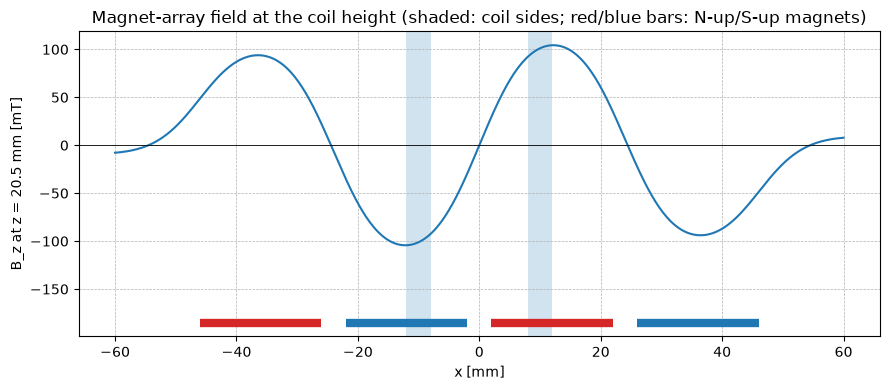

In [3]:
# 6. B_z across the array at the coil's mid-height (y = 0), 3D self-consistent model
x_line = np.linspace(-60, 60, 601)
bz_line = Bz_3d(x_line, np.zeros_like(x_line), np.full_like(x_line, 20.5), Ms)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_line, bz_line * 1e3, "-")
for xa, xb in sides:
    ax.axvspan(xa, xb, alpha=0.2)
for x1, x2, s in magnets:
    ax.hlines(-185, x1, x2, linewidth=6, color="tab:red" if s > 0 else "tab:blue")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xlabel("x [mm]")
ax.set_ylabel("B_z at z = 20.5 mm [mT]")
ax.set_title("Magnet-array field at the coil height (shaded: coil sides; red/blue bars: N-up/S-up magnets)")
ax.grid(True, linestyle="--", linewidth=0.5)
fig.tight_layout()
plt.savefig("Images/Week5_ex2_Bz_at_coil_height.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Hypothesis 1 - The virtual force is wrong on non-magnetic objects

The virtual force method gets the force from the change in field energy when the selected objects are moved by a tiny amount. On copper and air, which have μr = 1, that energy change is a small difference between large numbers, and the coil here is meshed coarsely (MaxLength 20 mm on a 4 x 10 mm cross-section). The Lorentz force J × B doesn't have that problem for a current-carrying conductor. If the normal force is a virtual-force error, the Lorentz force on the same coil should give F_z ≈ 0, and the air slot, which carries no current and can't feel any force, should still show one in the virtual calculation.

The companion notebook `Week5_ex2_force_check.ipynb` rebuilds the same model (same geometry, mesh and setup, new project name) and solves it once with five force calculations side by side.

In [4]:
# 7. All force calculations from the same solve, pulled once from the companion project's force table
check = pd.read_csv("Week5_ex2_force_check.csv").set_index("force")
check["Force_z / |Force_x| [%]"] = check["Force_z"] / check["Force_x"].abs() * 100
check.loc["coil_vir + slot_vir"] = check.loc["force_coil_vir"] + check.loc["force_slot_vir"]
check.loc["coil_vir + slot_vir", "Force_z / |Force_x| [%]"] = np.nan

# 8. Lorentz thrust against the 3D self-consistent model
F_lorentz = abs(check.loc["force_coil_lorentz", "Force_x"])
F_model = models["|F_x| [N]"].iloc[-1]
summary = pd.DataFrame({
    "quantity": ["Lorentz |F_x| [N]", "3D self-consistent model |F_x| [N]", "Lorentz / model - 1 [%]",
                 "virtual (coil + slot) / Lorentz - 1 [%]", "magnet side F_x / coil Lorentz F_x [-]"],
    "value": [F_lorentz, F_model, (F_lorentz / F_model - 1) * 100,
              (check.loc["force_mover", "Force_x"] / F_lorentz - 1) * 100,
              check.loc["force_magnet_side", "Force_x"] / check.loc["force_coil_lorentz", "Force_x"]],
})
display(check.round(4))
summary.round(4)

,Force_x,Force_y,Force_z,Force_z / |Force_x| [%]
force,,,,
force_mover,4.7854,0.0396,1.1846,24.7543
force_coil_lorentz,4.9802,0.0001,-0.0160,-0.3216
force_coil_vir,4.7541,0.0319,0.6197,13.0357
force_slot_vir,0.5641,0.0388,-1.3758,-243.9075
force_magnet_side,-5.0570,-0.0710,-6.8673,-135.7966
coil_vir + slot_vir,5.3182,0.0707,-0.7560,NaN


,quantity,value
0,Lorentz |F_x| [N],4.9802
1,3D self-consistent model |F_x| [N],4.9698
2,Lorentz / model - 1 [%],0.2096
3,virtual (coil + slot) / Lorentz - 1 [%],-3.9105
4,magnet side F_x / coil Lorentz F_x [-],-1.0154


**Hypothesis 1 confirmed.**

- The first row reproduces the original model exactly (F_x = 4.785 N, F_z = 1.185 N), so the companion is solving the same problem.
- The Lorentz force on the coil gives F_z = -0.016 N, 0.3% of the thrust, and it points down toward the plate as the image attraction should. F_y drops to 0.00006 N. The symmetry argument holds.
- The air slot, which has no current and μr = 1, picks up 1.38 N in z and 0.56 N in x from the virtual calculation. That force can't be real.
- The virtual forces aren't even additive: coil alone plus slot alone gives F_z = -0.76 N, while the two together give +1.18 N. The result depends on which objects are grouped, which only makes sense for a numerical artifact.
- The magnet side carries the reaction in x to within 1.5% (ratio -1.015 against the Lorentz thrust), but its virtual F_z is -6.9 N. With hundreds of newtons pulling the magnets onto the plate internally, a fraction of a percent of residual is enough to produce that, so it's the same kind of error on a set of strongly loaded objects.

The Lorentz thrust, 4.980 N, lands 0.2% above the 3D self-consistent charge model. The 3.7% that looked left over in section 3 was also the virtual-force error, this time in x: the virtual result on coil + slot is 3.9% below the Lorentz force from the same solve.

## 5. Final conclusion

The physics of this 1-slot motor matches the textbook picture. The thrust is N·I·L·B_z summed over the two coil sides, and once the model includes the finite magnet length and the thin magnets' self-demagnetization, it agrees with the solver's Lorentz force to 0.2%. The normal force is zero by symmetry, and the Lorentz force confirms that (0.3% of the thrust, pointing toward the plate). The blind 2D prediction of 5.4 N was about 9% high, for the two reasons the 3D model adds.

What broke was the measurement, not the theory: the virtual force on non-magnetic objects. On the coil + air slot set the original notebook uses, it adds a 1.18 N normal force that isn't there and takes 3.9% off the thrust, and it gives a nonzero force on an air region that can't feel any. For a coil in a field with no iron of its own, the Lorentz force (`is_virtual=False`) is the one to trust; the virtual force belongs on objects with μr ≠ 1. The coarse coil mesh (MaxLength 20 mm) is the likely reason the error is this large here, but that wasn't tested. The same effect probably explains the constant force offset on the coils in Week5_ex3, which is also an air-stator model with virtual force on non-magnetic objects.